# Tahap 10 — Uji Robustness Granularitas (D13)

Tahap ini menguji Opsi 3 (per-SKU dengan fallback) pada kalender evaluasi yang
sama dengan D1 (gerai×merek). Prediksi Opsi 3 selalu di-*rollup* sebelum
dibandingkan. RF tidak berbeda signifikan sehingga D1 dipertahankan; LSTM
secara signifikan mendukung Opsi 3 sebagai arah pengembangan masa depan.
SARIMAX dikecualikan karena intermittent demand per-SKU memperbesar risiko
non-konvergensi tanpa nilai tambah proporsional.

In [1]:
from __future__ import annotations
from pathlib import Path
import json
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
CFG = yaml.safe_load((ROOT / "config.yaml").read_text(encoding="utf-8"))
SEED = int(CFG["seed"])
np.random.seed(SEED)

def rp(*parts: str) -> Path:
    """Resolve a repo-relative path (parts are path fragments under the repo root)."""
    return ROOT.joinpath(*parts)

BRAND_COLORS = {"OPPO": "#0072B2", "Realme": "#D55E00", "Samsung": "#009E73",
                "Vivo": "#CC79A7", "Xiaomi": "#E69F00"}
ALGO_COLORS = {"SARIMAX": "#0072B2", "RF": "#D55E00", "LSTM": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 4.5),
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 12})

In [2]:
import hashlib
from pandas.testing import assert_frame_equal

RETRAIN = False
SAVE_ARTIFACTS = False
ZERO_WEEK_THRESHOLD = 0.50
TRAILING_WINDOW = 12
N_WEEKS_EXPECTED = 184
BRAND_FALLBACK_SOURCE = ("rf", "gt")
RESULT_COLUMNS = ["algoritma", "MAE_D1", "MAE_Opsi3_rollup", "MASE_Opsi3",
                  "dm_pvalue_D1_vs_Opsi3", "kesimpulan",
                  "pct_SKU_direct_vs_fallback_per_gerai"]
PREDICTION_COLUMNS = ["store", "brand", "week_start", "y_true", "y_pred", "algoritma"]
D13_TEST_CALENDAR = pd.date_range("2024-10-21", "2025-06-30", freq="W-MON")
D13_BUNDLED_HASHES = {
    "granularity_check_verdict.csv": "F87DEBD86C61F7D361E2FFCC687C2CEE686B3D83FFE56EAF4C41BD7DEB32DB80",
    "granularity_check_predictions.parquet": "2729D7EB7EC96E03CE506F5391BBB3AD4C7A1E2EEE9FD8B29DB63731148192B5",
}

## Fungsi D13 dan jalur pelatihan opsional

Semua fungsi di bawah bersifat lokal pada notebook. Jalur berat hanya dipanggil
saat `RETRAIN=True`; eksekusi baku tidak melatih atau menimpa artefak.

In [3]:
def sku_brand_map(clean: pd.DataFrame) -> dict[str, str]:
    """Map every SKU to its sole brand."""
    n_multi = int((clean.groupby("sku")["brand"].nunique() > 1).sum())
    assert n_multi == 0, "SKU terpetakan ke lebih dari satu merek."
    return clean.groupby("sku")["brand"].first().to_dict()


def aggregate_weekly_store_sku(clean: pd.DataFrame) -> pd.DataFrame:
    """Build the full store-SKU weekly grid, filling valid zero-sales weeks."""
    clean = clean.copy()
    clean["week_start"] = pd.to_datetime(clean["week_start"])
    grouped = (clean.groupby(["store", "sku", "week_start"], as_index=False)["qty"].sum()
               .rename(columns={"qty": "units"}))
    stores, skus = sorted(clean["store"].unique()), sorted(clean["sku"].unique())
    weeks = pd.date_range(clean["week_start"].min(), clean["week_start"].max(), freq="W-MON")
    full = pd.MultiIndex.from_product([stores, skus, weeks], names=["store", "sku", "week_start"])
    weekly = (grouped.set_index(["store", "sku", "week_start"]).reindex(full, fill_value=0)
              .reset_index().sort_values(["store", "sku", "week_start"]).reset_index(drop=True))
    weekly["units"] = weekly["units"].astype(int)
    weekly["brand"] = weekly["sku"].map(sku_brand_map(clean))
    assert len(weeks) == N_WEEKS_EXPECTED
    return weekly


def classify_series(weekly_sku: pd.DataFrame, threshold: float = ZERO_WEEK_THRESHOLD) -> pd.DataFrame:
    """Classify a series as fallback only when zero-week fraction is strictly above threshold."""
    classified = (weekly_sku.assign(_zero=weekly_sku["units"].eq(0))
                  .groupby(["store", "sku", "brand"])["_zero"].mean().reset_index()
                  .rename(columns={"_zero": "zero_week_frac"}))
    classified["strategy"] = np.where(classified["zero_week_frac"] > threshold, "fallback", "direct")
    return classified.sort_values(["store", "brand", "sku"]).reset_index(drop=True)


def _week_monday(ts: pd.Timestamp) -> pd.Timestamp:
    return pd.Timestamp(ts).to_period("W").start_time


def build_features_for_series(series_df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """Build past-only RF/LSTM features for one SKU series."""
    df = series_df.sort_values("week_start").reset_index(drop=True).copy()
    units = df["units"].astype(float)
    for lag in range(1, int(cfg["lags"]) + 1):
        df[f"lag_{lag}"] = units.shift(lag)
    for window in cfg["rolling_windows"]:
        df[f"roll_mean_{window}"] = units.rolling(window).mean().shift(1)
    first_window = int(cfg["rolling_windows"][0])
    df[f"roll_std_{first_window}"] = units.rolling(first_window).std().shift(1)
    weeks = pd.to_datetime(df["week_start"])
    df["weekofyear"] = weeks.dt.isocalendar().week.astype(int)
    df["month"] = weeks.dt.month.astype(int)
    lebaran = [_week_monday(x) for x in pd.to_datetime(["2022-05-02", "2023-04-22", "2024-04-10", "2025-03-31"])]
    ramadan = {day - pd.Timedelta(weeks=offset) for day in lebaran for offset in range(1, 5)}
    lebaran_window = {day + pd.Timedelta(weeks=offset) for day in lebaran for offset in range(-1, 2)}
    harbolnas = {_week_monday(pd.Timestamp(year=year, month=month, day=day))
                 for year in range(int(weeks.dt.year.min()), int(weeks.dt.year.max()) + 1)
                 for month, day in [(11, 11), (12, 12)]}
    df["is_ramadan"] = weeks.isin(ramadan).astype(int)
    df["is_lebaran_window"] = weeks.isin(lebaran_window).astype(int)
    df["is_harbolnas"] = weeks.isin(harbolnas).astype(int)
    df["year_trend"] = np.arange(len(df))
    for harmonic in range(1, int(cfg["fourier_harmonics"]) + 1):
        angle = 2 * np.pi * harmonic * np.arange(len(df)) / int(cfg["seasonal_period"])
        df[f"fourier_sin_{harmonic}"], df[f"fourier_cos_{harmonic}"] = np.sin(angle), np.cos(angle)
    return df


def _sku_features(weekly_sku: pd.DataFrame, gt: pd.DataFrame, cfg: dict,
                  keys: list[tuple[str, str]]) -> dict[str, pd.DataFrame]:
    """Create local features only for direct SKU series."""
    merged = weekly_sku.merge(gt[["week_start", "brand", "gt_index"]], on=["week_start", "brand"],
                              how="left", validate="many_to_one")
    assert not merged["gt_index"].isna().any()
    requested = set(keys)
    return {f"{store}|{sku}": build_features_for_series(frame, cfg)
            for (store, sku), frame in merged.groupby(["store", "sku"])
            if (store, sku) in requested}


def train_cutoff_week(weeks: pd.DatetimeIndex, train_ratio: float = 0.8) -> pd.Timestamp:
    unique = pd.DatetimeIndex(sorted(pd.Index(weeks).unique()))
    return unique[int(np.floor(len(unique) * train_ratio))]


def temporal_masks(weeks: pd.Series, cutoff: pd.Timestamp) -> tuple[pd.Series, pd.Series]:
    is_test = pd.to_datetime(weeks) >= cutoff
    return ~is_test, is_test


def resolve_feature_columns(columns, cfg: dict, variant: str = "gt") -> list[str]:
    """Resolve notebook configuration wildcards in frame order."""
    resolved = []
    for spec in cfg["feature_variants"][variant]:
        if spec.endswith("*"):
            resolved.extend(c for c in columns if c.startswith(spec[:-1]))
        elif spec in columns:
            resolved.append(spec)
        else:
            raise KeyError(f"Kolom fitur hilang: {spec}")
    return list(dict.fromkeys(resolved))


def make_supervised(frame: pd.DataFrame, cfg: dict, variant: str = "gt"):
    columns = resolve_feature_columns(frame.columns, cfg, variant)
    usable = frame.dropna(subset=columns).reset_index(drop=True)
    return usable[columns], usable["units"].astype(float), pd.DatetimeIndex(usable["week_start"])


def _param_grid(cfg: dict) -> dict:
    return {key: cfg["random_forest"][key] for key in ("n_estimators", "max_depth", "max_features", "min_samples_leaf")}


def forecast_direct_rf(feats: dict[str, pd.DataFrame], cfg: dict, cutoff: pd.Timestamp) -> pd.DataFrame:
    """Train local RFs for direct SKUs, using the common temporal cutoff."""
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
    rows = []
    for key, frame in feats.items():
        X, y, index = make_supervised(frame, cfg, "gt")
        train, test = temporal_masks(pd.Series(index), cutoff)
        model = GridSearchCV(RandomForestRegressor(random_state=SEED, n_jobs=-1), _param_grid(cfg),
                             cv=TimeSeriesSplit(5), scoring="neg_mean_absolute_error", n_jobs=-1)
        model.fit(X.loc[train.to_numpy()], y.loc[train.to_numpy()])
        store, sku = key.split("|")
        rows.append(pd.DataFrame({"store": store, "sku": sku, "brand": frame["brand"].iloc[0],
                                  "week_start": index[test.to_numpy()], "y_true": y.loc[test.to_numpy()].to_numpy(),
                                  "y_pred": np.clip(model.predict(X.loc[test.to_numpy()]), 0, None)}))
    return pd.concat(rows, ignore_index=True) if rows else _empty_sku_pred()


def _lstm_channels(columns, cfg: dict) -> list[str]:
    return ["units"] + [c for c in resolve_feature_columns(columns, cfg, "gt")
                          if not c.startswith(("lag_", "roll_"))]


def _lstm_sequences(frame: pd.DataFrame, cfg: dict, cutoff: pd.Timestamp):
    from sklearn.preprocessing import MinMaxScaler
    frame = frame.sort_values("week_start").reset_index(drop=True)
    weeks, channels, length = pd.DatetimeIndex(frame["week_start"]), _lstm_channels(frame.columns, cfg), int(cfg["lags"])
    values = frame[channels].astype(float).to_numpy()
    scaler = MinMaxScaler().fit(values[weeks < cutoff])
    scaled = scaler.transform(values)
    umin, urange = float(scaler.data_min_[0]), float(scaler.data_max_[0] - scaler.data_min_[0]) or 1.0
    X = np.asarray([scaled[t-length:t] for t in range(length, len(frame))], dtype="float32")
    y = ((values[length:, 0] - umin) / urange).astype("float32")
    index = weeks[length:]
    train, test = temporal_masks(pd.Series(index), cutoff)
    return X[train.to_numpy()], y[train.to_numpy()], X[test.to_numpy()], index[test.to_numpy()], values[length:, 0][test.to_numpy()], umin, urange


def forecast_direct_lstm(feats: dict[str, pd.DataFrame], cfg: dict, cutoff: pd.Timestamp) -> pd.DataFrame:
    """Train local LSTMs for direct SKUs; Keras is lazily imported."""
    import keras
    from keras import layers
    params = cfg.get("lstm", {})
    rows = []
    for key, frame in feats.items():
        X_train, y_train, X_test, index, y_true, umin, urange = _lstm_sequences(frame, cfg, cutoff)
        keras.utils.set_random_seed(SEED)
        model = keras.Sequential([keras.Input(X_train.shape[1:]), layers.LSTM(params.get("units", 64)),
                                  layers.Dropout(params.get("dropout", .2)), layers.Dense(1)])
        model.compile(loss="mse", optimizer="adam")
        early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=params.get("patience", 10), restore_best_weights=True)
        model.fit(X_train, y_train, epochs=params.get("epochs", 200), batch_size=params.get("batch_size", 16),
                  validation_split=.2, shuffle=False, callbacks=[early], verbose=0)
        store, sku = key.split("|")
        rows.append(pd.DataFrame({"store": store, "sku": sku, "brand": frame["brand"].iloc[0],
                                  "week_start": index, "y_true": y_true,
                                  "y_pred": np.clip(model.predict(X_test, verbose=0).ravel() * urange + umin, 0, None)}))
    return pd.concat(rows, ignore_index=True) if rows else _empty_sku_pred()


def _empty_sku_pred() -> pd.DataFrame:
    return pd.DataFrame(columns=["store", "sku", "brand", "week_start", "y_true", "y_pred"])


def trailing_share(sku_units: pd.Series, brand_units: pd.Series, t: pd.Timestamp,
                   weeks: pd.DatetimeIndex, window: int, n_sku_in_brand: int) -> float:
    """Return the SKU share using only strictly earlier observations."""
    pos = weeks.get_loc(pd.Timestamp(t))
    prior = weeks[:pos]
    recent = prior[-window:]
    denominator = float(brand_units.reindex(recent).sum())
    if denominator > 0:
        return float(sku_units.reindex(recent).sum()) / denominator
    denominator = float(brand_units.reindex(prior).sum())
    if denominator > 0:
        return float(sku_units.reindex(prior).sum()) / denominator
    return 1.0 / max(n_sku_in_brand, 1)


def forecast_fallback(weekly_sku: pd.DataFrame, fallback_keys: list[tuple[str, str]],
                      d1_brand_pred: pd.DataFrame, test_weeks: pd.DatetimeIndex,
                      all_weeks: pd.DatetimeIndex, window: int = TRAILING_WINDOW) -> pd.DataFrame:
    """Allocate the RF D1 fallback forecast by strictly trailing SKU share."""
    sku_week = {key: group.set_index("week_start")["units"].astype(float) for key, group in weekly_sku.groupby(["store", "sku"])}
    brand_week = {key: group.groupby("week_start")["units"].sum().astype(float) for key, group in weekly_sku.groupby(["store", "brand"])}
    n_sku = weekly_sku.groupby(["store", "brand"])["sku"].nunique().to_dict()
    sku_to_brand = weekly_sku.groupby("sku")["brand"].first().to_dict()
    brand_pred = d1_brand_pred.set_index(["store", "brand", "week_start"])["y_pred"]
    rows = []
    for store, sku in fallback_keys:
        brand = sku_to_brand[sku]
        shares = [trailing_share(sku_week[(store, sku)], brand_week[(store, brand)], t, all_weeks, window, n_sku[(store, brand)]) for t in test_weeks]
        rows.append(pd.DataFrame({"store": store, "sku": sku, "brand": brand, "week_start": test_weeks,
                                  "y_true": [float(sku_week[(store, sku)].get(t, 0)) for t in test_weeks],
                                  "y_pred": [float(brand_pred[(store, brand, t)]) * share for t, share in zip(test_weeks, shares)]}))
    return pd.concat(rows, ignore_index=True) if rows else _empty_sku_pred()


def rollup_to_store_brand(sku_preds: pd.DataFrame) -> pd.DataFrame:
    """Roll direct and fallback SKU predictions up to the comparable D1 unit."""
    return (sku_preds.groupby(["store", "brand", "week_start"], as_index=False)[["y_true", "y_pred"]].sum()
            .sort_values(["store", "brand", "week_start"]).reset_index(drop=True))


def mae(y_true, y_pred) -> float:
    return float(np.mean(np.abs(np.asarray(y_true, float) - np.asarray(y_pred, float))))


def naive_mae_lookup(naive: pd.DataFrame) -> dict[tuple[str, str], float]:
    return {(store, brand): mae(group["y_true"], group["y_pred"])
            for (store, brand), group in naive.groupby(["store", "brand"])}


def _mean_series_mae(frame: pd.DataFrame) -> float:
    return float(np.mean([mae(group["y_true"], group["y_pred"])
                          for _, group in frame.groupby(["store", "brand"])]))


def _mean_series_mase(frame: pd.DataFrame, naive_mae: dict[tuple[str, str], float]) -> float:
    values = [mae(group["y_true"], group["y_pred"]) / naive_mae[(store, brand)]
              for (store, brand), group in frame.groupby(["store", "brand"])
              if naive_mae.get((store, brand), 0) > 0]
    return float(np.mean(values)) if values else float("nan")


def diebold_mariano(y_true, pred1, pred2) -> dict:
    """Perform the pooled one-step, two-sided DM test."""
    from scipy import stats
    differential = (np.asarray(y_true, float) - np.asarray(pred1, float)) ** 2 - (np.asarray(y_true, float) - np.asarray(pred2, float)) ** 2
    n, mean = len(differential), float(np.mean(differential))
    variance = float(np.mean((differential - mean) ** 2)) / n
    better = 1 if mean < 0 else (2 if mean > 0 else 0)
    if variance <= 0 or n < 2:
        return {"p_value": 1.0 if mean == 0 else 0.0, "better": better}
    stat = mean / np.sqrt(variance) * np.sqrt((n - 1) / n)
    return {"p_value": float(2 * stats.t.cdf(-abs(stat), df=n - 1)), "better": better}


def dm_from_frames(first: pd.DataFrame, second: pd.DataFrame) -> dict:
    keys = ["store", "brand", "week_start"]
    merged = first[keys + ["y_true", "y_pred"]].merge(second[keys + ["y_true", "y_pred"]], on=keys, suffixes=("_1", "_2"))
    assert len(merged) == len(first) == len(second)
    assert np.allclose(merged["y_true_1"], merged["y_true_2"])
    return diebold_mariano(merged["y_true_1"], merged["y_pred_1"], merged["y_pred_2"])


def _conclusion(mae_d1: float, mae_opt3: float, p_value: float, alpha: float = .05) -> str:
    if p_value >= alpha:
        return "tak berbeda signifikan (D1 dipertahankan)"
    return "D1 (gerai×merek) signifikan lebih baik" if mae_d1 < mae_opt3 else "Opsi 3 (per-SKU) signifikan lebih baik"


def _per_store_strategy_str(classification: pd.DataFrame) -> str:
    parts = []
    for store, group in classification.groupby("store"):
        direct, total = int((group["strategy"] == "direct").sum()), len(group)
        parts.append(f"{store}: {direct}/{total} direct ({100 * direct / total:.0f}%)")
    return "; ".join(parts)


def run_granularity_check(cfg: dict, save: bool = False) -> dict:
    """Run the optional full SKU recomputation and return all analytical frames."""
    clean = pd.read_parquet(rp("data", "interim", "transactions_clean.parquet"))
    gt = pd.read_csv(rp("data", "interim", "google_trends.csv"), parse_dates=["week_start"])
    weekly_sku = aggregate_weekly_store_sku(clean)
    all_weeks = pd.DatetimeIndex(sorted(weekly_sku["week_start"].unique()))
    cutoff = train_cutoff_week(all_weeks, float(cfg["train_ratio"]))
    test_weeks = all_weeks[all_weeks >= cutoff]
    classification = classify_series(weekly_sku)
    direct = [(row.store, row.sku) for row in classification[classification.strategy == "direct"].itertuples()]
    fallback = [(row.store, row.sku) for row in classification[classification.strategy == "fallback"].itertuples()]
    fallback_pred = forecast_fallback(weekly_sku, fallback, pd.read_parquet(rp("reports", "results", "predictions_rf_gt.parquet")), test_weeks, all_weeks)
    feats = _sku_features(weekly_sku, gt, cfg, direct)
    direct_predictions = {"RF": forecast_direct_rf(feats, cfg, cutoff), "LSTM": forecast_direct_lstm(feats, cfg, cutoff)}
    naive = naive_mae_lookup(pd.read_parquet(rp("reports", "results", "predictions_naive.parquet")))
    verdict_rows, prediction_frames = [], []
    for algorithm, direct_pred in direct_predictions.items():
        option_three = rollup_to_store_brand(pd.concat([direct_pred, fallback_pred], ignore_index=True))
        d1 = pd.read_parquet(rp("reports", "results", f"predictions_{algorithm.lower()}_gt.parquet"))
        dm = dm_from_frames(d1, option_three)
        mae_d1, mae_o3 = _mean_series_mae(d1), _mean_series_mae(option_three)
        verdict_rows.append({"algoritma": algorithm, "MAE_D1": round(mae_d1, 4), "MAE_Opsi3_rollup": round(mae_o3, 4),
                             "MASE_Opsi3": round(_mean_series_mase(option_three, naive), 4),
                             "dm_pvalue_D1_vs_Opsi3": round(dm["p_value"], 4),
                             "kesimpulan": _conclusion(mae_d1, mae_o3, dm["p_value"]),
                             "pct_SKU_direct_vs_fallback_per_gerai": _per_store_strategy_str(classification)})
        prediction_frames.append(option_three.assign(algoritma=algorithm))
    verdict, predictions = pd.DataFrame(verdict_rows)[RESULT_COLUMNS], pd.concat(prediction_frames, ignore_index=True)[PREDICTION_COLUMNS]
    if save:
        verdict.to_csv(rp("reports", "results", "granularity_check_verdict.csv"), index=False)
        predictions.to_parquet(rp("reports", "results", "granularity_check_predictions.parquet"), index=False)
    return {"verdict": verdict, "predictions": predictions, "classification": classification,
            "n_direct": len(direct), "n_fallback": len(fallback)}


def load_bundled_robustness() -> dict:
    """Load the audited D13 artifacts without recomputation or persistence."""
    verdict = pd.read_csv(rp("reports", "results", "granularity_check_verdict.csv"))
    predictions = pd.read_parquet(rp("reports", "results", "granularity_check_predictions.parquet"))
    return {"verdict": verdict, "predictions": predictions}


def _sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest().upper()


def verify_robustness_outputs(
    retrain: bool,
    save_artifacts: bool,
    robustness_mode: str,
    robustness_result: dict[str, pd.DataFrame],
    classification: pd.DataFrame,
    results_dir: Path,
    *,
    d1_predictions: dict[str, pd.DataFrame] | None = None,
    naive_predictions: pd.DataFrame | None = None,
) -> str:
    """Validate D13 outputs with bundled locks or retrained semantics."""
    expected_mode = "retrained" if retrain else "bundled"
    assert robustness_mode == expected_mode, (robustness_mode, expected_mode)
    assert set(robustness_result) == {"verdict", "predictions"}
    verdict = robustness_result["verdict"]
    predictions = robustness_result["predictions"]
    assert isinstance(verdict, pd.DataFrame) and isinstance(predictions, pd.DataFrame)
    assert verdict.columns.tolist() == RESULT_COLUMNS and verdict.shape == (2, 7)
    assert predictions.columns.tolist() == PREDICTION_COLUMNS and predictions.shape == (1480, 6)
    assert set(verdict["algoritma"]) == {"RF", "LSTM"}
    assert not verdict.isna().any().any()
    assert not predictions.isna().any().any()
    assert np.isfinite(predictions[["y_true", "y_pred"]].to_numpy(dtype=float)).all()
    assert (predictions["y_pred"] >= 0).all()
    assert not predictions.duplicated(["store", "brand", "week_start", "algoritma"]).any()
    assert predictions.groupby("algoritma").size().to_dict() == {"LSTM": 740, "RF": 740}
    assert predictions.groupby(["algoritma", "store", "brand"]).ngroups == 40
    assert predictions.groupby(["algoritma", "store", "brand"])["week_start"].nunique().eq(37).all()

    for algorithm, frame in predictions.groupby("algoritma"):
        assert frame.groupby(["store", "brand"]).ngroups == 20, algorithm
        calendar = pd.DatetimeIndex(sorted(pd.to_datetime(frame["week_start"]).unique()))
        assert calendar.equals(D13_TEST_CALENDAR), algorithm
    rf_keys = (predictions[predictions["algoritma"].eq("RF")]
               .sort_values(["store", "brand", "week_start"]).reset_index(drop=True))
    lstm_keys = (predictions[predictions["algoritma"].eq("LSTM")]
                 .sort_values(["store", "brand", "week_start"]).reset_index(drop=True))
    assert rf_keys[["store", "brand", "week_start"]].equals(
        lstm_keys[["store", "brand", "week_start"]])
    assert np.array_equal(rf_keys["y_true"].to_numpy(), lstm_keys["y_true"].to_numpy())

    assert len(classification) == 60
    assert (classification["strategy"] == "direct").sum() == 11
    assert (classification["strategy"] == "fallback").sum() == 49

    if retrain:
        assert d1_predictions is not None and set(d1_predictions) == {"RF", "LSTM"}
        assert naive_predictions is not None
        naive_lookup = naive_mae_lookup(naive_predictions)
        expected_strategy = _per_store_strategy_str(classification)
        indexed_verdict = verdict.set_index("algoritma")
        for algorithm in ("RF", "LSTM"):
            option_three = predictions[predictions["algoritma"].eq(algorithm)].reset_index(drop=True)
            d1 = d1_predictions[algorithm].reset_index(drop=True)
            assert len(d1) == 740
            assert set(["store", "brand", "week_start", "y_true", "y_pred"]).issubset(d1.columns)
            ordered_d1 = d1.sort_values(["store", "brand", "week_start"]).reset_index(drop=True)
            ordered_option = option_three.sort_values(["store", "brand", "week_start"]).reset_index(drop=True)
            assert ordered_d1[["store", "brand", "week_start"]].equals(
                ordered_option[["store", "brand", "week_start"]])
            assert np.array_equal(ordered_d1["y_true"].to_numpy(), ordered_option["y_true"].to_numpy())

            dm = dm_from_frames(d1, option_three)
            mae_d1 = _mean_series_mae(d1)
            mae_option = _mean_series_mae(option_three)
            mase_option = _mean_series_mase(option_three, naive_lookup)
            row = indexed_verdict.loc[algorithm]
            assert np.isclose(float(row["MAE_D1"]), round(mae_d1, 4), atol=5e-5, rtol=0)
            assert np.isclose(float(row["MAE_Opsi3_rollup"]), round(mae_option, 4), atol=5e-5, rtol=0)
            assert np.isclose(float(row["MASE_Opsi3"]), round(mase_option, 4), atol=5e-5, rtol=0)
            assert np.isclose(float(row["dm_pvalue_D1_vs_Opsi3"]), round(dm["p_value"], 4), atol=5e-5, rtol=0)
            assert row["kesimpulan"] == _conclusion(mae_d1, mae_option, dm["p_value"])
            assert row["pct_SKU_direct_vs_fallback_per_gerai"] == expected_strategy
    else:
        disk_verdict = pd.read_csv(results_dir / "granularity_check_verdict.csv")
        disk_predictions = pd.read_parquet(results_dir / "granularity_check_predictions.parquet")
        assert_frame_equal(verdict, disk_verdict, check_dtype=True, check_like=False,
                           atol=1e-12, rtol=1e-12)
        assert_frame_equal(predictions, disk_predictions, check_dtype=True, check_like=False,
                           atol=1e-12, rtol=1e-12)
        locked = verdict.set_index("algoritma")
        rf, lstm = locked.loc["RF"], locked.loc["LSTM"]
        assert not rf["kesimpulan"].startswith("Opsi 3")
        assert rf["dm_pvalue_D1_vs_Opsi3"] > 0.05
        assert abs(rf["MAE_D1"] - 1.3995) < 1e-10
        assert abs(rf["MAE_Opsi3_rollup"] - 1.4085) < 1e-10
        assert lstm["kesimpulan"].startswith("Opsi 3")
        assert lstm["dm_pvalue_D1_vs_Opsi3"] < 1e-3
        assert lstm["MAE_Opsi3_rollup"] < lstm["MAE_D1"]
        for filename, expected_hash in D13_BUNDLED_HASHES.items():
            assert _sha256(results_dir / filename) == expected_hash

    if retrain and save_artifacts:
        disk_verdict = pd.read_csv(results_dir / "granularity_check_verdict.csv")
        disk_predictions = pd.read_parquet(results_dir / "granularity_check_predictions.parquet")
        assert_frame_equal(verdict, disk_verdict, check_dtype=True, check_like=False,
                           atol=1e-12, rtol=1e-12)
        assert_frame_equal(predictions, disk_predictions, check_dtype=True, check_like=False,
                           atol=1e-12, rtol=1e-12)

    if not retrain:
        return "bundled"
    return "retrained/saved" if save_artifacts else "retrained/no-save"

## Memuat bukti D13 dan perbandingan visual

Default memuat artefak yang telah diaudit. `RETRAIN=True` menjalankan ulang jalur
per-SKU; keluaran hanya ditulis bila `SAVE_ARTIFACTS=True`.

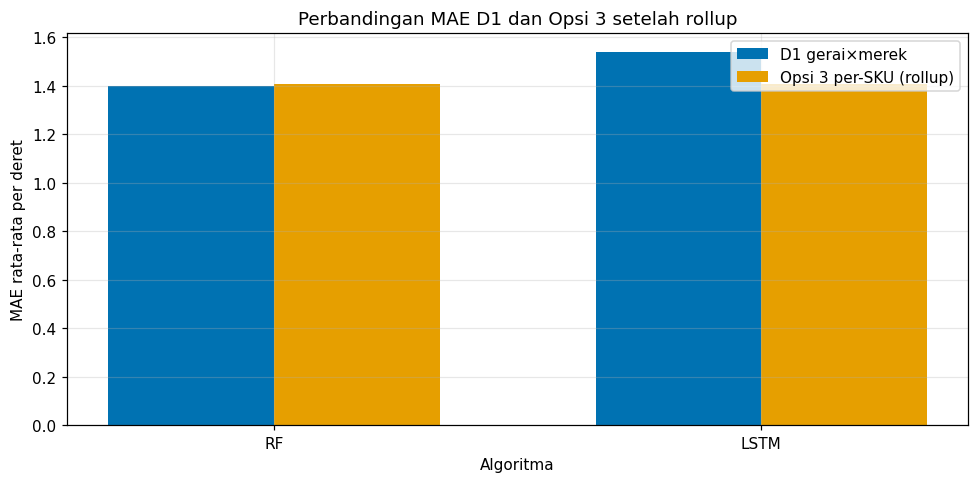

In [4]:
clean_data = pd.read_parquet(rp("data", "interim", "transactions_clean.parquet"))
weekly_sku = aggregate_weekly_store_sku(clean_data)
classification = classify_series(weekly_sku)
assert len(classification) == 60 and (classification["strategy"] == "direct").sum() == 11 and (classification["strategy"] == "fallback").sum() == 49

if RETRAIN:
    heavy_result = run_granularity_check(CFG, save=SAVE_ARTIFACTS)
    robustness_result = {key: heavy_result[key] for key in ("verdict", "predictions")}
    robustness_mode = "retrained"
else:
    robustness_result = load_bundled_robustness()
    robustness_mode = "bundled"

verdict_plot = robustness_result["verdict"].set_index("algoritma")
fig, ax = plt.subplots()
x = np.arange(2)
width = .34
ax.bar(x - width / 2, [verdict_plot.loc[name, "MAE_D1"] for name in ["RF", "LSTM"]], width,
       color="#0072B2", label="D1 gerai×merek")
ax.bar(x + width / 2, [verdict_plot.loc[name, "MAE_Opsi3_rollup"] for name in ["RF", "LSTM"]], width,
       color="#E69F00", label="Opsi 3 per-SKU (rollup)")
ax.set_xticks(x, ["RF", "LSTM"])
ax.set_title("Perbandingan MAE D1 dan Opsi 3 setelah rollup")
ax.set_xlabel("Algoritma")
ax.set_ylabel("MAE rata-rata per deret")
ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)

In [5]:
verification_inputs = {}
if RETRAIN:
    verification_inputs = {
        "d1_predictions": {
            algorithm: pd.read_parquet(
                rp("reports", "results", f"predictions_{algorithm.lower()}_gt.parquet"))
            for algorithm in ("RF", "LSTM")
        },
        "naive_predictions": pd.read_parquet(
            rp("reports", "results", "predictions_naive.parquet")),
    }
verified_robustness_mode = verify_robustness_outputs(
    RETRAIN,
    SAVE_ARTIFACTS,
    robustness_mode,
    robustness_result,
    classification,
    rp("reports", "results"),
    **verification_inputs,
)

probe_weeks = pd.date_range("2024-01-01", periods=4, freq="W-MON")
probe_sku = pd.Series([2., 1., 999., 999.], index=probe_weeks)
probe_brand = pd.Series([4., 2., 999., 999.], index=probe_weeks)
assert trailing_share(probe_sku, probe_brand, probe_weeks[2], probe_weeks, 12, 2) == .5
future_sku, future_brand = probe_sku.copy(), probe_brand.copy()
future_sku.iloc[2:], future_brand.iloc[2:] = 0., 1_000_000.
assert trailing_share(future_sku, future_brand, probe_weeks[2], probe_weeks, 12, 2) == .5
assert len(ax.patches) == 4 and [tick.get_text() for tick in ax.get_xticklabels()] == ["RF", "LSTM"]
assert ax.get_legend() is not None and "Perbandingan" in ax.get_title() and ax.get_xlabel() == "Algoritma"
if RETRAIN:
    print(f"✅ Tahap 10 (D13) [{verified_robustness_mode}]: hasil retraining "
          "lulus validasi metrik, DM, kesimpulan, dan persistensi sesuai mode")
else:
    print("✅ Tahap 10 (D13) [bundled]: hasil campuran — RF mempertahankan D1; "
          "LSTM mendukung Opsi 3 per-SKU")

✅ Tahap 10 (D13) [bundled]: hasil campuran — RF mempertahankan D1; LSTM mendukung Opsi 3 per-SKU
